In [2]:
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Read the CSV file into a pandas DataFrame with correct delimiter
df = pd.read_csv('../preprocess/parking_time_series_with_features_1_hour.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])

# Set timestamp column as index (assuming it represents time)
df.set_index('Time', inplace=True)

# Ensure the data is sorted by timestamp (just in case)
df.sort_index(inplace=True)


# Convert exogenous features to appropriate data types
df['day_of_year'] = df['day_of_year'].astype(int)
df['weekday'] = df['weekday'].astype(int)
df['hour'] = df['hour'].astype(int)
df['is_holiday'] = df['is_holiday'].astype(int)

exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='h')  # 'h' stands for hourly frequency

# Extract exogenous features for training and test sets
train_exog = train_data[exogenous_features]
test_exog = test_data[exogenous_features]

# Fit ARIMA model using auto_arima
model = auto_arima(train_data['Parkings'], 
                              exogenous=train_exog, 
                              stationary=False,
                              seasonal=True, 
                              #d=1, 
                              #D=1,
                              m=24,  # Daily seasonality in hourly data
                              trace=True,
                              error_action='ignore', 
                              suppress_warnings=True,
                              #stepwise=True
                              )

model.fit(train_data['Parkings'])

# Generate predictions
predictions = model.predict(n_periods=len(test_data))


Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[24] intercept   : AIC=inf, Time=8.64 sec
 ARIMA(0,0,0)(0,0,0)[24] intercept   : AIC=29731.508, Time=0.03 sec
 ARIMA(1,0,0)(1,0,0)[24] intercept   : AIC=inf, Time=2.41 sec
 ARIMA(0,0,1)(0,0,1)[24] intercept   : AIC=26086.120, Time=4.73 sec
 ARIMA(0,0,0)(0,0,0)[24]             : AIC=31027.681, Time=0.02 sec
 ARIMA(0,0,1)(0,0,0)[24] intercept   : AIC=27313.046, Time=0.19 sec
 ARIMA(0,0,1)(1,0,1)[24] intercept   : AIC=25676.470, Time=6.83 sec
 ARIMA(0,0,1)(1,0,0)[24] intercept   : AIC=25463.134, Time=3.30 sec
 ARIMA(0,0,1)(2,0,0)[24] intercept   : AIC=25497.955, Time=21.10 sec
 ARIMA(0,0,1)(2,0,1)[24] intercept   : AIC=inf, Time=27.33 sec
 ARIMA(0,0,0)(1,0,0)[24] intercept   : AIC=inf, Time=2.15 sec
 ARIMA(1,0,1)(1,0,0)[24] intercept   : AIC=22682.497, Time=3.79 sec
 ARIMA(1,0,1)(0,0,0)[24] intercept   : AIC=24357.567, Time=0.35 sec
 ARIMA(1,0,1)(2,0,0)[24] intercept   : AIC=22658.309, Time=24.86 sec
 ARIMA(1,0,1)(2,0,1)[24] i

Mean Absolute Error (MAE): 313.31189225803826
Mean Squared Error (MSE): 123244.4030782041
Root Mean Squared Error (RMSE): 351.0618223022892


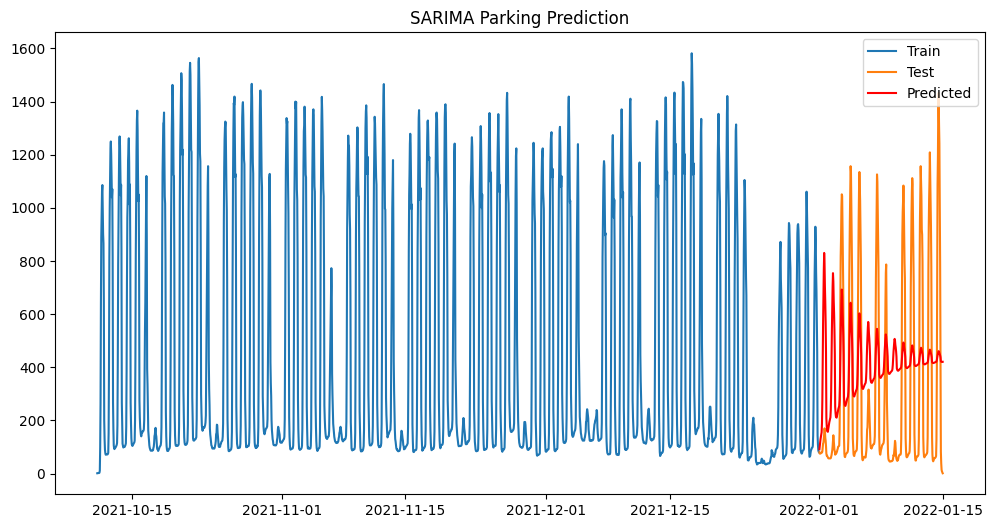

In [3]:

# Calculate evaluation metrics
mae = mean_absolute_error(test_data['Parkings'], predictions)
mse = mean_squared_error(test_data['Parkings'], predictions)
rmse = np.sqrt(mse)

print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.title('SARIMA Parking Prediction')
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Read the CSV file into a pandas DataFrame with correct delimiter
df = pd.read_csv('../preprocess/parking_time_series_with_features.csv', delimiter=',')

# Convert timestamp column to DateTime format
df['Time'] = pd.to_datetime(df['Time'])

# Set timestamp column as index (assuming it represents time)
df.set_index('Time', inplace=True)

# Ensure the data is sorted by timestamp (just in case)
df.sort_index(inplace=True)

exogenous_features = ["day_of_year","weekday","hour","is_holiday"]

# Fit ARIMA model using auto_arima
model = auto_arima(df["Parkings"],
	exogenous=df[exogenous_features],
	trace=True,
	error_action="ignore",
	suppress_warnings=True)

# Generate predictions
predictions = model.predict(n_periods=len(df), exogenous=df[exogenous_features])

# Calculate evaluation metrics
mae = mean_absolute_error(df['Parkings'], predictions)
mse = mean_squared_error(df['Parkings'], predictions)
rmse = np.sqrt(mse)

print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=903702.474, Time=37.76 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=917091.768, Time=1.12 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=907993.509, Time=1.35 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=909531.911, Time=5.66 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=917089.768, Time=0.57 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=903868.737, Time=19.47 sec


KeyboardInterrupt: 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Read the CSV file into a pandas DataFrame with correct delimiter
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Convert timestamp column to DateTime format
df['Time'] = pd.to_datetime(df['Time'])

# Set timestamp column as index (assuming it represents time)
df.set_index('Time', inplace=True)

# Ensure the data is sorted by timestamp (just in case)
df.sort_index(inplace=True)

exogenous_features = ["day_of_year","weekday","hour","is_holiday"]

# Downsample the data to hourly frequency
df_hourly = df.resample('15min').mean()

# Convert exogenous features to appropriate data types
df_hourly['day_of_year'] = df_hourly['day_of_year'].astype(int)
df_hourly['weekday'] = df_hourly['weekday'].astype(int)
df_hourly['hour'] = df_hourly['hour'].astype(int)
df_hourly['is_holiday'] = df_hourly['is_holiday'].astype(int)

# Make the time series data stationary using rolling mean and standard deviation
rolling_window = 96  # 24-hour window for hourly data
df_hourly['Parkings_rolling_mean'] = df_hourly['Parkings'].rolling(window=rolling_window).mean()
df_hourly['Parkings_rolling_std'] = df_hourly['Parkings'].rolling(window=rolling_window).std()
df_hourly['Parkings_stationary'] = (df_hourly['Parkings'] - df_hourly['Parkings_rolling_mean']) / df_hourly['Parkings_rolling_std']


# Fit ARIMA model using auto_arima
model = auto_arima(df_hourly["Parkings"],
	exogenous=df[exogenous_features],
	trace=True,
	error_action="ignore",
	suppress_warnings=True)

# Generate predictions
predictions = model.predict(n_periods=len(df_hourly), exogenous=df_hourly[exogenous_features])

# Calculate evaluation metrics
mae = mean_absolute_error(df_hourly['Parkings'], predictions)
mse = mean_squared_error(df_hourly['Parkings'], predictions)
rmse = np.sqrt(mse)

print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=94102.788, Time=1.60 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=96999.729, Time=0.06 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=94412.011, Time=0.28 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=95177.013, Time=0.54 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=96997.729, Time=0.04 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=94110.958, Time=1.01 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=94100.788, Time=1.08 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=94176.169, Time=0.73 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=94263.533, Time=0.32 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=94102.788, Time=2.10 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=94197.167, Time=0.36 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=94060.017, Time=2.20 sec
 ARIMA(4,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=4.58 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=93705.669, Time=4.78 sec
 ARIMA(2,1,3)(0,0,0)[0] i